In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score


In [28]:
# Load dataset
housing = fetch_california_housing()

# Create DataFrame
data = pd.DataFrame(housing.data, columns=housing.feature_names)

# Add target column
data["Price"] = housing.target




In [29]:
# select the feature
X = data[['AveRooms']].values
y = data['Price'].values

In [30]:
#split data 
X_train, X_test,y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42
)

In [31]:
#feature scaling
scalar = StandardScaler()

X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

In [45]:
w = 0
b = 0
cost_history = []

learning_rate = 0.01
epochs = 1000

n = len(X_train_scaled)

for i in range(epochs):
    # Predictions
    y_pred = w * X_train_scaled.flatten() + b

    # Gradients
    dw = (1/n) * np.sum((y_pred - y_train) * X_train_scaled.flatten())
    db = (1/n) * np.sum(y_pred - y_train)

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # Compute cost
    cost = (1/(2*n)) * np.sum((y_pred - y_train) ** 2)
    cost_history.append(cost)

    # Print every 100 epochs
    if i % 100 == 0:
        print(f"Epoch {i}, Cost = {cost:.4f}")

# Predictions on test data
y_pred_gd = w * X_test_scaled.flatten() + b

Epoch 0, Cost = 2.8149
Epoch 100, Cost = 0.9414
Epoch 200, Cost = 0.6904
Epoch 300, Cost = 0.6568
Epoch 400, Cost = 0.6523
Epoch 500, Cost = 0.6517
Epoch 600, Cost = 0.6516
Epoch 700, Cost = 0.6516
Epoch 800, Cost = 0.6516
Epoch 900, Cost = 0.6516


In [46]:
print("Gradient descent")
print("-----------------")
print("Weight:",w)
print("Bias:",b)
print("MSE:", mean_squared_error(y_test,y_pred_gd))
print("R2 score:", r2_score(y_test,y_pred_gd))




Gradient descent
-----------------
Weight: 0.18323090648660517
Bias: 2.0718574888450205
MSE: 1.292327655590046
R2 score: 0.013798228607320828


In [47]:
# -------------------
# Normal Equation
# -------------------

import numpy as np

# Add a column of ones for the intercept term
X_train_ne = np.c_[np.ones((len(X_train), 1)), X_train]
X_test_ne = np.c_[np.ones((len(X_test), 1)), X_test]

# Compute theta using the normal equation
theta = np.linalg.inv(X_train_ne.T @ X_train_ne) @ X_train_ne.T @ y_train

# Predict on the test set
y_pred_ne = X_test_ne @ theta

In [48]:
print("\nNormal eqn")
print("-----------------")
print("Intercept:",theta[0])
print("slope:",theta[1])
print("MSE:", mean_squared_error(y_test,y_pred_ne))
print("R2 score:", r2_score(y_test,y_pred_ne))




Normal eqn
-----------------
Intercept: 1.6547622685968417
slope: 0.07675558963126736
MSE: 1.2923314440807299
R2 score: 0.013795337532284901


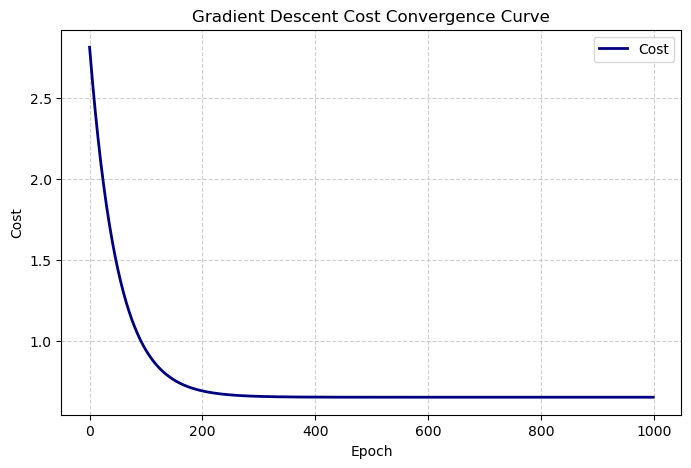

In [49]:
plt.figure(figsize=(8,5))

plt.plot(cost_history, color='navy', linewidth=2, label='Cost')

plt.title("Gradient Descent Cost Convergence Curve")
plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

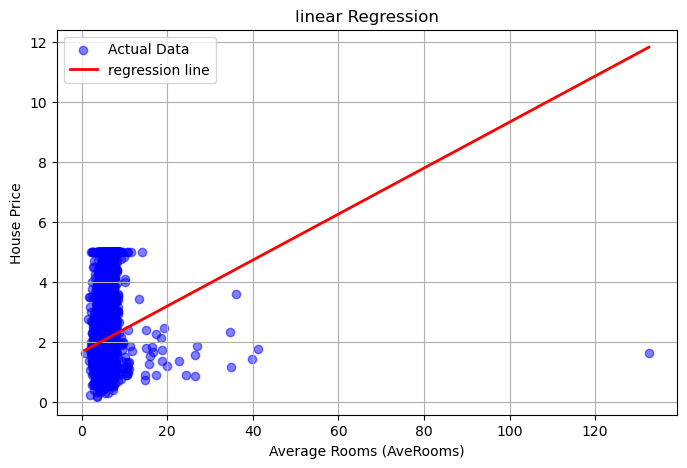

In [44]:
index=np.argsort(X_test.flatten())
plt.figure(figsize=(8,5))

# Training data
plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Actual Data')




plt.plot(
    X_test.flatten()[index],
     y_pred_ne[index],
    color='red',
    linewidth=2,
    label='regression line')

plt.title("linear Regression")
plt.xlabel("Average Rooms (AveRooms)")
plt.ylabel("House Price")
plt.legend()
plt.grid(True)

plt.show()